# Comprensión de los datos, EDA y preparación

## 1. Carga de los datos

Se carga el archivo original proporcionado por la institución.
En esta etapa se revisará su estructura y calidad, sin modificar
los registros ni aplicar transformaciones.


In [1]:
from pathlib import Path
import sys

import pandas as pd


directorio_actual = Path.cwd()

if (directorio_actual / "src").is_dir():
    ROOT = directorio_actual
elif (directorio_actual.parent / "src").is_dir():
    ROOT = directorio_actual.parent
else:
    raise FileNotFoundError(
        "Abre el notebook desde la raíz del proyecto "
        "o desde su carpeta notebooks."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.utils import load_raw


df = load_raw()

df.head()


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


## 2. Diagnóstico inicial de calidad

### 2.1. Dimensiones y tipos de datos

Se revisa la cantidad de registros y columnas, los tipos detectados
por pandas y el número de valores no ausentes por variable.

In [2]:
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")

df.info(verbose=True, show_counts=True)

Filas: 2,930
Columnas: 82
<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17 

In [3]:
resumen_nulos = pd.DataFrame({
    "cantidad_nulos": df.isna().sum(),
    "porcentaje_nulos": df.isna().mean().mul(100).round(2)
})

resumen_nulos = resumen_nulos.sort_values(
    "cantidad_nulos",
    ascending=False
)

resumen_nulos.loc[resumen_nulos["cantidad_nulos"] > 0]

,cantidad_nulos,porcentaje_nulos
Pool QC,2917,99.56
Misc Feature,2824,96.38
Alley,2732,93.24
Fence,2358,80.48
Mas Vnr Type,1775,60.58
Fireplace Qu,1422,48.53
Lot Frontage,490,16.72
Garage Qual,159,5.43
Garage Yr Blt,159,5.43
Garage Cond,159,5.43


### 2.2. Revisión de valores ausentes

Las columnas con mayor proporción de valores interpretados como ausentes
son Pool QC (99,56%), Misc Feature (96,38%), Alley (93,24%) y Fence (80,48%).

También destacan Mas Vnr Type (60,58%), Fireplace Qu (48,53%) y
Lot Frontage (16,72%).

Estos porcentajes no justifican por sí solos eliminar las variables.
Antes de definir su tratamiento, se revisará si las ausencias representan
información desconocida, inexistencia de una característica o una
categoría convertida automáticamente en nulo durante la lectura del CSV.

En esta etapa solo se documenta el diagnóstico; no se modifica el dataset.

In [4]:
# Lectura auxiliar para inspeccionar los textos originales del CSV.
df_texto = load_raw(
    dtype=str,
    keep_default_na=False
)

columnas_revisar = [
    "Pool QC",
    "Misc Feature",
    "Alley",
    "Fence",
    "Mas Vnr Type",
    "Fireplace Qu"
]

for columna in columnas_revisar:
    print(f"\n--- {columna} ---")
    print(df_texto[columna].value_counts(dropna=False))


--- Pool QC ---
Pool QC
NA    2917
Ex       4
Gd       4
TA       3
Fa       2
Name: count, dtype: int64

--- Misc Feature ---
Misc Feature
NA      2824
Shed      95
Gar2       5
Othr       4
Elev       1
TenC       1
Name: count, dtype: int64

--- Alley ---
Alley
NA      2732
Grvl     120
Pave      78
Name: count, dtype: int64

--- Fence ---
Fence
NA       2358
MnPrv     330
GdPrv     118
GdWo      112
MnWw       12
Name: count, dtype: int64

--- Mas Vnr Type ---
Mas Vnr Type
None       1752
BrkFace     880
Stone       249
BrkCmn       25
             23
CBlock        1
Name: count, dtype: int64

--- Fireplace Qu ---
Fireplace Qu
NA    1422
Gd     744
TA     600
Fa      75
Po      46
Ex      43
Name: count, dtype: int64


### 2.3. Comprobación de los valores originales

La lectura auxiliar permitió identificar que parte de los valores
detectados inicialmente como nulos corresponden a códigos escritos
en el archivo original.

En Mas Vnr Type se encontraron 1.752 registros con el texto "None"
y 23 campos vacíos. La lectura inicial agrupaba ambas situaciones
como 1.775 valores ausentes, por lo que es necesario diferenciarlas.

En Pool QC, Misc Feature, Alley, Fence y Fireplace Qu se encontró
el código "NA". Su interpretación deberá considerar el significado
de cada variable y su coherencia con otras características de la vivienda.

No se eliminarán estas columnas únicamente por su porcentaje inicial
de valores ausentes. El tratamiento definitivo se establecerá durante
la preparación de datos y quedará documentado.

La lectura auxiliar se utiliza solo para inspeccionar los códigos
originales. El DataFrame principal todavía no se modifica.

In [5]:
resumen_integridad = pd.Series({
    "filas": len(df),
    "columnas": df.shape[1],
    "filas_completamente_duplicadas": df.duplicated().sum(),
    "Order_duplicados": df["Order"].duplicated().sum(),
    "PID_duplicados": df["PID"].duplicated().sum(),
    "SalePrice_nulos": df["SalePrice"].isna().sum(),
    "SalePrice_cero_o_negativo": df["SalePrice"].le(0).sum()
})

resumen_integridad

filas                             2930
columnas                            82
filas_completamente_duplicadas       0
Order_duplicados                     0
PID_duplicados                       0
SalePrice_nulos                      0
SalePrice_cero_o_negativo            0
dtype: int64

### 2.4. Duplicados e integridad de la variable objetivo

El dataset contiene 2.930 registros y 82 columnas.

No se encontraron filas completamente duplicadas ni valores repetidos
en los identificadores Order y PID.

La variable objetivo SalePrice no presenta valores ausentes, iguales
a cero ni negativos.

Por estos criterios no se requiere eliminar registros. Sin embargo,
todavía deben revisarse los rangos de las variables, las posibles
inconsistencias y los valores extremos.

### 2.5. Revisión de rangos numéricos

Se inspeccionan mínimos, máximos, mediana y cuartiles para identificar
valores que requieran revisión.

Un valor extremo no se considerará automáticamente un error ni será
eliminado sin analizar su contexto.

In [6]:
resumen_numerico = (
    df.drop(columns=["Order", "PID"])
      .describe()
      .T
)

resumen_numerico[
    ["count", "min", "25%", "50%", "75%", "max"]
].round(2)

,count,min,25%,50%,75%,max
MS SubClass,2930.0,20.0,20.00,50.0,70.00,190.0
Lot Frontage,2440.0,21.0,58.00,68.0,80.00,313.0
Lot Area,2930.0,1300.0,7440.25,9436.5,11555.25,215245.0
Overall Qual,2930.0,1.0,5.00,6.0,7.00,10.0
Overall Cond,2930.0,1.0,5.00,5.0,6.00,9.0
Year Built,2930.0,1872.0,1954.00,1973.0,2001.00,2010.0
Year Remod/Add,2930.0,1950.0,1965.00,1993.0,2004.00,2010.0
Mas Vnr Area,2907.0,0.0,0.00,0.0,164.00,1600.0
BsmtFin SF 1,2929.0,0.0,0.00,370.0,734.00,5644.0
BsmtFin SF 2,2929.0,0.0,0.00,0.0,0.00,1526.0


### 2.6. Comprobación de coherencia temporal

El resumen numérico muestra un valor de 2207 en Garage Yr Blt,
superior al año máximo de venta registrado (2010).

Se revisarán los registros cuyo año de construcción, remodelación
o construcción del garaje sea posterior al año de venta.

Estas comprobaciones generan alertas para inspección. No modifican
los datos ni implican eliminar automáticamente los registros.

In [7]:
alertas_temporales = pd.DataFrame({
    "construccion_posterior_venta":
        df["Year Built"] > df["Yr Sold"],

    "remodelacion_posterior_venta":
        df["Year Remod/Add"] > df["Yr Sold"],

    "garaje_posterior_venta":
        df["Garage Yr Blt"] > df["Yr Sold"]
})

display(alertas_temporales.sum().rename("cantidad_alertas"))

columnas_revision = [
    "Order",
    "PID",
    "Year Built",
    "Year Remod/Add",
    "Garage Yr Blt",
    "Yr Sold",
    "Garage Type",
    "SalePrice"
]

display(
    df.loc[
        alertas_temporales.any(axis=1),
        columnas_revision
    ]
)

construccion_posterior_venta    1
remodelacion_posterior_venta    3
garaje_posterior_venta          2
Name: cantidad_alertas, dtype: int64

,Order,PID,Year Built,Year Remod/Add,Garage Yr Blt,Yr Sold,Garage Type,SalePrice
1702,1703,528120010,2007,2008,2007.0,2007,Detchd,260116
2180,2181,908154195,2008,2009,2008.0,2007,Attchd,183850
2181,2182,908154205,2007,2008,2007.0,2007,BuiltIn,184750
2260,2261,916384070,2006,2007,2207.0,2007,Attchd,267300


#### Resultado de la revisión temporal

Se identificaron cuatro registros con al menos una alerta temporal:

- Un registro presenta un año de construcción posterior al año de venta.
- Tres registros presentan un año de remodelación posterior al de venta.
- Dos registros presentan un año de construcción del garaje posterior
  al de venta.

Las categorías se superponen: las seis alertas corresponden a cuatro
registros distintos.

Destaca el registro Order = 2261, cuyo año de construcción del garaje
es 2207. Se considera una inconsistencia que requiere tratamiento,
pero no se dispone de evidencia para asignarle un año correcto.

Los demás registros también requieren revisión. Las diferencias
temporales no permiten determinar por sí solas qué campo es incorrecto.

Por ahora se conservan todos los registros sin modificar. Su tratamiento
se definirá y justificará en la etapa de preparación de datos.

### 2.7. Detección exploratoria de valores extremos

Se revisarán Lot Area, Gr Liv Area, Total Bsmt SF y SalePrice
mediante la regla del rango intercuartílico (IQR).

El IQR es la diferencia entre el tercer y el primer cuartil:
IQR = Q3 - Q1.

Se marcarán para revisión los valores inferiores a Q1 - 1,5 × IQR
o superiores a Q3 + 1,5 × IQR.

Esta regla identifica observaciones potencialmente atípicas,
pero no demuestra que sean errores. No se eliminarán ni modificarán
registros únicamente por superar estos límites.

Los límites calculados en esta sección se utilizarán solo para
el diagnóstico exploratorio, no como reglas de limpieza del modelo.

In [8]:
variables_revisar = [
    "Lot Area",
    "Gr Liv Area",
    "Total Bsmt SF",
    "SalePrice"
]

resultados_iqr = []

for columna in variables_revisar:
    serie = df[columna].dropna()

    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    fuera_de_rango = (
        (serie < limite_inferior)
        | (serie > limite_superior)
    )

    resultados_iqr.append({
        "variable": columna,
        "limite_inferior": limite_inferior,
        "limite_superior": limite_superior,
        "cantidad_marcada": fuera_de_rango.sum(),
        "porcentaje_sobre_validos": fuera_de_rango.mean() * 100
    })

resumen_iqr = pd.DataFrame(resultados_iqr).set_index("variable")

resumen_iqr.round(2)

,limite_inferior,limite_superior,cantidad_marcada,porcentaje_sobre_validos
variable,,,,
Lot Area,1267.75,17727.75,127,4.33
Gr Liv Area,200.88,2667.88,75,2.56
Total Bsmt SF,29.50,2065.50,123,4.20
SalePrice,3500.00,339500.00,137,4.68


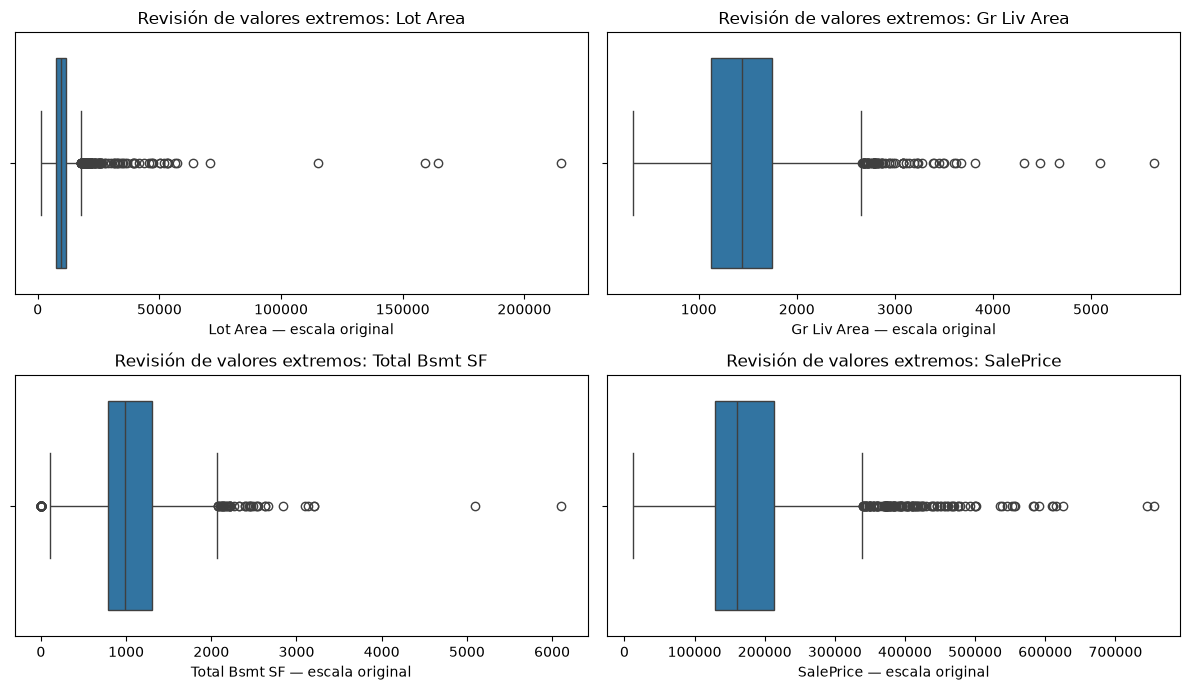

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, columna in zip(axes.flat, variables_revisar):
    sns.boxplot(
        data=df,
        x=columna,
        ax=ax,
        whis=1.5
    )

    ax.set_title(f"Revisión de valores extremos: {columna}")
    ax.set_xlabel(f"{columna} — escala original")

plt.tight_layout()
plt.show()

#### Resultado de la revisión de valores extremos

La regla de 1,5 × IQR identificó observaciones potencialmente atípicas
en las cuatro variables analizadas:

- Lot Area: 127 registros (4,33%).
- Gr Liv Area: 75 registros (2,56%).
- Total Bsmt SF: 123 registros (4,20%).
- SalePrice: 137 registros (4,68%).

Las cantidades corresponden a cada variable por separado y pueden
incluir las mismas viviendas.

Los gráficos muestran valores elevados alejados del rango central
en superficies y precios. Sin embargo, esto no demuestra que sean
errores: podrían representar propiedades con características
poco frecuentes.

En Total Bsmt SF, el límite inferior es 29,50. Por tanto, la regla
también marca superficies iguales a cero. Se deberá comprobar si
estos registros corresponden a viviendas sin sótano antes de
considerarlos inconsistentes.

En SalePrice, los registros marcados se encuentran por encima del
límite superior de 339.500, ya que el precio mínimo observado supera
el límite inferior de 3.500.

No se eliminarán ni modificarán registros únicamente por superar
los límites IQR. Estos resultados se utilizarán como diagnóstico
exploratorio, no como umbrales definitivos de limpieza.

### 2.8. Conclusiones del diagnóstico inicial

1. El dataset contiene 2.930 registros y 82 columnas.

2. No se detectaron filas completamente duplicadas ni repeticiones
   en los identificadores Order y PID.

3. SalePrice no presenta valores ausentes, iguales a cero ni negativos.

4. La lectura inicial de valores ausentes mezcla campos vacíos con
   códigos como "NA" y "None". Su tratamiento deberá considerar
   el significado de cada variable.

5. Se identificaron cuatro registros con alertas temporales.
   Destaca Garage Yr Blt = 2207, sin evidencia suficiente para
   asignarle directamente un año correcto.

6. Se detectaron posibles valores extremos en superficies y precios.
   No se consideran errores automáticamente.

El dataset original se mantiene sin modificaciones. Las decisiones
de limpieza y transformación se implementarán posteriormente en
src/data_prep.py y se justificarán en este notebook.

## 3. Análisis exploratorio de datos (EDA)

El análisis exploratorio busca identificar patrones en las variables
y sus relaciones con el precio de venta.

Los resultados describen asociaciones presentes en el dataset;
no se interpretarán como relaciones causales.

### 3.1. Distribución del precio de venta

Se analiza la distribución de SalePrice y se comparan su media
y mediana para comprender cómo se distribuyen los precios.

In [10]:
resumen_precio = pd.Series({
    "cantidad": df["SalePrice"].count(),
    "minimo": df["SalePrice"].min(),
    "primer_cuartil": df["SalePrice"].quantile(0.25),
    "mediana": df["SalePrice"].median(),
    "media": df["SalePrice"].mean(),
    "tercer_cuartil": df["SalePrice"].quantile(0.75),
    "maximo": df["SalePrice"].max()
})

resumen_precio.round(2)

cantidad            2930.00
minimo             12789.00
primer_cuartil    129500.00
mediana           160000.00
media             180796.06
tercer_cuartil    213500.00
maximo            755000.00
dtype: float64

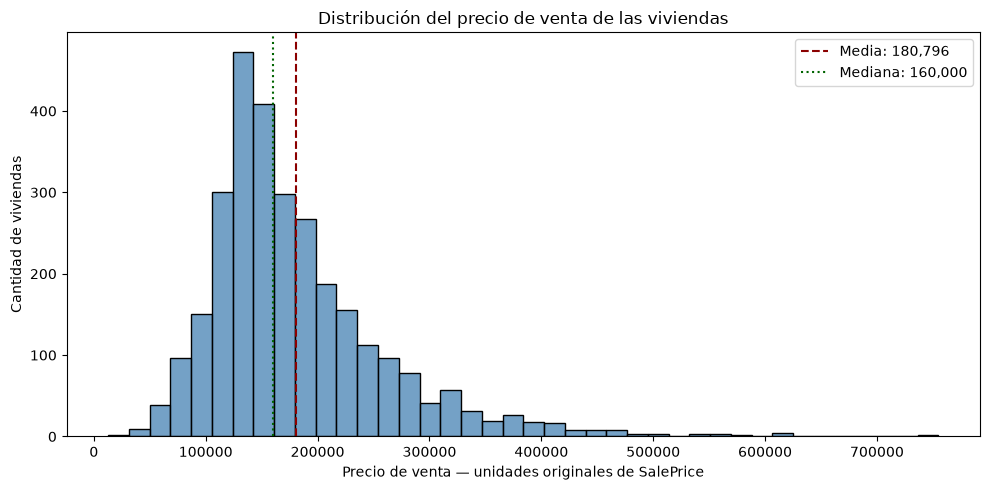

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

IMAGES_DIR = ROOT / "images"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

media_precio = df["SalePrice"].mean()
mediana_precio = df["SalePrice"].median()

fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=df,
    x="SalePrice",
    bins=40,
    color="steelblue",
    ax=ax
)

ax.axvline(
    media_precio,
    color="darkred",
    linestyle="--",
    label=f"Media: {media_precio:,.0f}"
)

ax.axvline(
    mediana_precio,
    color="darkgreen",
    linestyle=":",
    label=f"Mediana: {mediana_precio:,.0f}"
)

ax.set_title("Distribución del precio de venta de las viviendas")
ax.set_xlabel("Precio de venta — unidades originales de SalePrice")
ax.set_ylabel("Cantidad de viviendas")
ax.legend()

fig.tight_layout()

fig.savefig(
    IMAGES_DIR / "eda_distribucion_saleprice.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

#### Hallazgo 1: distribución desigual del precio de venta

SalePrice presenta una distribución asimétrica hacia la derecha,
con una concentración de viviendas en los rangos bajos y medios
y una cola de precios elevados.

La media es 180.796,06 y la mediana es 160.000.
El 50% central de los precios se encuentra entre 129.500 y 213.500.
El rango completo va desde 12.789 hasta 755.000.

Implicancia para el negocio:
un único precio de referencia no representa adecuadamente toda la
variedad de viviendas. La evaluación deberá considerar si la calidad
de las estimaciones cambia entre rangos de precio, en lugar de
depender únicamente de una métrica global.

Decisión para las siguientes etapas:
se conservarán los precios originales. Se podrá evaluar una
transformación del objetivo durante el modelado, pero este gráfico
no justifica aplicarla automáticamente ni eliminar viviendas caras.

### 3.2. Relación entre superficie habitable y precio

Se explora la relación entre Gr Liv Area y SalePrice para identificar
tendencias, dispersión y observaciones que requieran revisión.

Una asociación entre ambas variables no se interpretará como
un efecto causal ni permitirá estimar por sí sola el valor de
una ampliación.

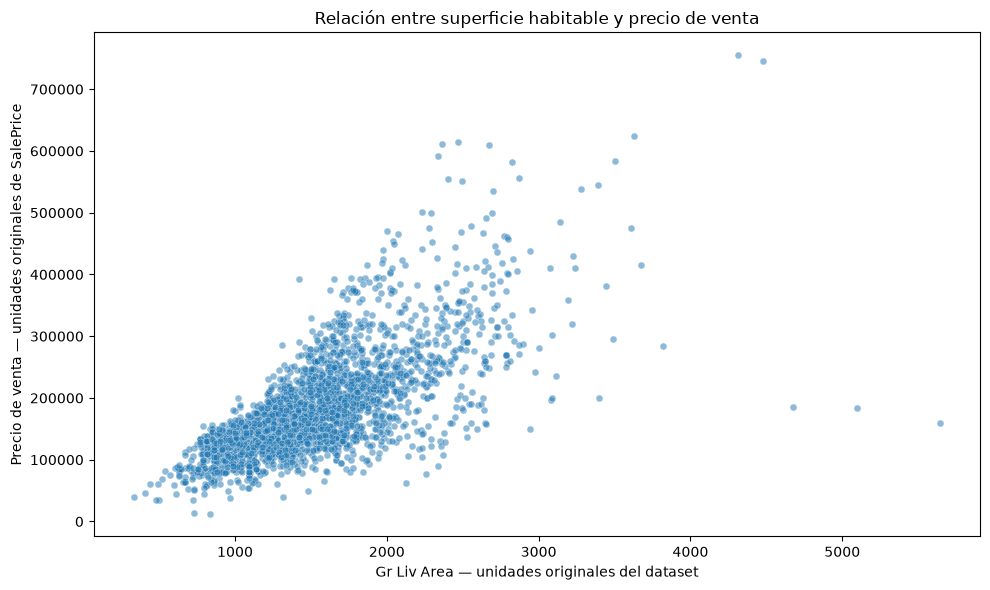

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Gr Liv Area",
    y="SalePrice",
    alpha=0.5,
    s=25,
    ax=ax
)

ax.set_title("Relación entre superficie habitable y precio de venta")
ax.set_xlabel("Gr Liv Area — unidades originales del dataset")
ax.set_ylabel("Precio de venta — unidades originales de SalePrice")

fig.tight_layout()

fig.savefig(
    IMAGES_DIR / "eda_superficie_precio.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [13]:
correlaciones_superficie = pd.Series({
    "Pearson": df["Gr Liv Area"].corr(
        df["SalePrice"],
        method="pearson"
    ),
    "Spearman": df["Gr Liv Area"].corr(
        df["SalePrice"],
        method="spearman"
    )
})

correlaciones_superficie.round(3)

Pearson     0.707
Spearman    0.723
dtype: float64

#### Hallazgo 2: relación entre superficie habitable y precio

Gr Liv Area presenta una asociación positiva con SalePrice:
la correlación de Pearson es 0,707 y la de Spearman es 0,723.

El gráfico muestra que las viviendas con mayor superficie habitable
tienden a registrar precios superiores. Sin embargo, existen diferencias
considerables de precio entre viviendas con superficies similares.

También se observan propiedades de gran superficie con precios
relativamente bajos respecto de la tendencia general. Estos registros
se conservarán mientras no exista evidencia de que contienen errores.

Implicancia para el negocio:
la superficie habitable es una variable candidata relevante para
estimar precios, pero no resulta suficiente por sí sola. Debe analizarse
junto con otras características de las viviendas.

Limitación:
la asociación observada no demuestra que aumentar la superficie
produzca un incremento específico del precio ni garantiza el desempeño
predictivo del modelo.

### 3.3. Calidad general y precio de venta

Se comparan los precios entre los niveles registrados en Overall Qual.

Se revisa también la cantidad de viviendas de cada nivel para evitar
interpretar de la misma manera grupos numerosos y grupos con pocos
registros.

In [14]:
resumen_calidad = (
    df.groupby("Overall Qual")["SalePrice"]
      .agg(
          cantidad="count",
          mediana="median",
          media="mean",
          minimo="min",
          maximo="max"
      )
      .round(2)
)

resumen_calidad

,cantidad,mediana,media,minimo,maximo
Overall Qual,,,,,
1,4,50150.0,48725.00,13100,81500
2,13,57625.0,52325.31,12789,82000
3,40,81200.0,83185.98,37900,139600
4,226,105000.0,106485.10,34900,256000
5,825,133000.0,134752.52,55993,301600
6,732,159500.0,162130.32,76000,415000
7,602,200000.0,205025.76,82500,383970
8,350,264530.5,270913.59,122000,538000
9,107,360000.0,368336.77,150000,611657


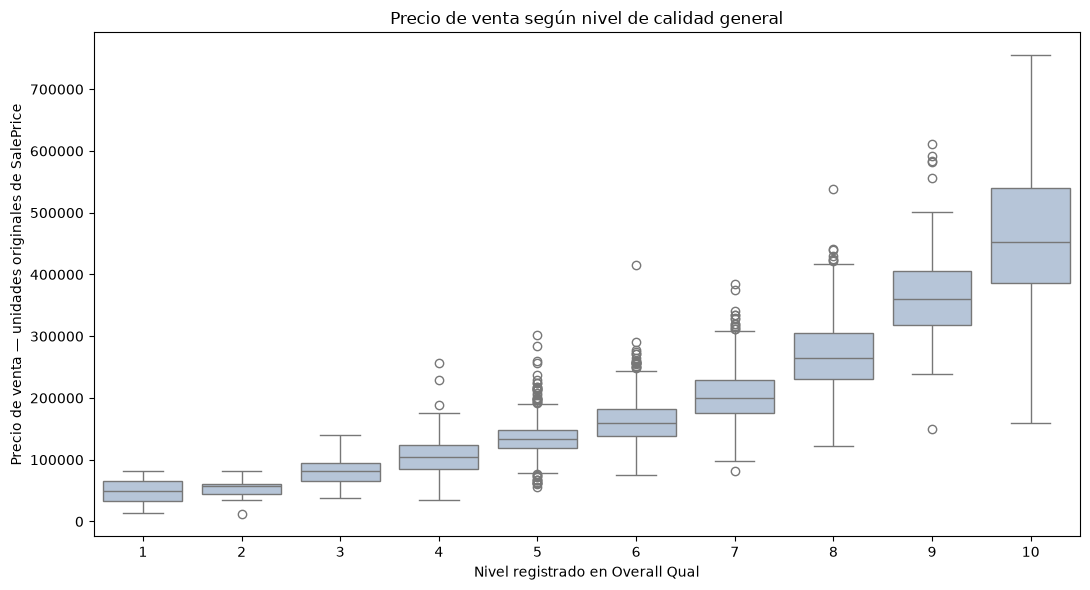

In [15]:
fig, ax = plt.subplots(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="Overall Qual",
    y="SalePrice",
    color="lightsteelblue",
    ax=ax
)

ax.set_title("Precio de venta según nivel de calidad general")
ax.set_xlabel("Nivel registrado en Overall Qual")
ax.set_ylabel("Precio de venta — unidades originales de SalePrice")

fig.tight_layout()

fig.savefig(
    IMAGES_DIR / "eda_calidad_precio.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

#### Hallazgo 3: calidad general y diferencias de precio

Las medianas de SalePrice aumentan conforme sube el nivel registrado
en Overall Qual. Por ejemplo:

- Nivel 5: mediana de 133.000, con 825 viviendas.
- Nivel 6: mediana de 159.500, con 732 viviendas.
- Nivel 7: mediana de 200.000, con 602 viviendas.
- Nivel 8: mediana de 264.530,50, con 350 viviendas.
- Nivel 9: mediana de 360.000, con 107 viviendas.
- Nivel 10: mediana de 451.950, con 31 viviendas.

El gráfico también muestra variación de precios dentro de cada nivel
y superposición entre niveles.

Los grupos tienen tamaños distintos. Los niveles 1 y 2 cuentan con
solo 4 y 13 registros, respectivamente, por lo que sus resultados
requieren especial cautela.

Implicancia para el negocio:
la calidad general es una variable candidata relevante para apoyar
la estimación de precios y comparar viviendas. No obstante, debe
considerarse junto con superficie, ubicación y otras características.

Limitación:
estas diferencias no demuestran que mejorar la calidad de una vivienda
produzca un incremento de precio equivalente a la diferencia entre
las medianas de los grupos.

### 3.4. Barrio y precio de venta

Se comparan las distribuciones de SalePrice entre los barrios
registrados en Neighborhood.

Las diferencias observadas pueden estar relacionadas tanto con
la ubicación como con la composición de las viviendas de cada
barrio. Este análisis no separa esos factores ni demuestra
un efecto causal de la ubicación.

In [16]:
resumen_barrio = (
    df.groupby("Neighborhood")["SalePrice"]
      .agg(
          cantidad="count",
          mediana="median",
          media="mean"
      )
      .sort_values("mediana")
      .round(2)
)

resumen_barrio

,cantidad,mediana,media
Neighborhood,,,
MeadowV,37,88250.0,95756.49
BrDale,30,106000.0,105608.33
IDOTRR,93,106500.0,103752.90
OldTown,239,119900.0,123991.89
Edwards,194,125000.0,130843.38
BrkSide,108,126750.0,124756.25
Blueste,10,130500.0,143590.00
Sawyer,151,135000.0,136751.15
SWISU,48,136200.0,135071.94


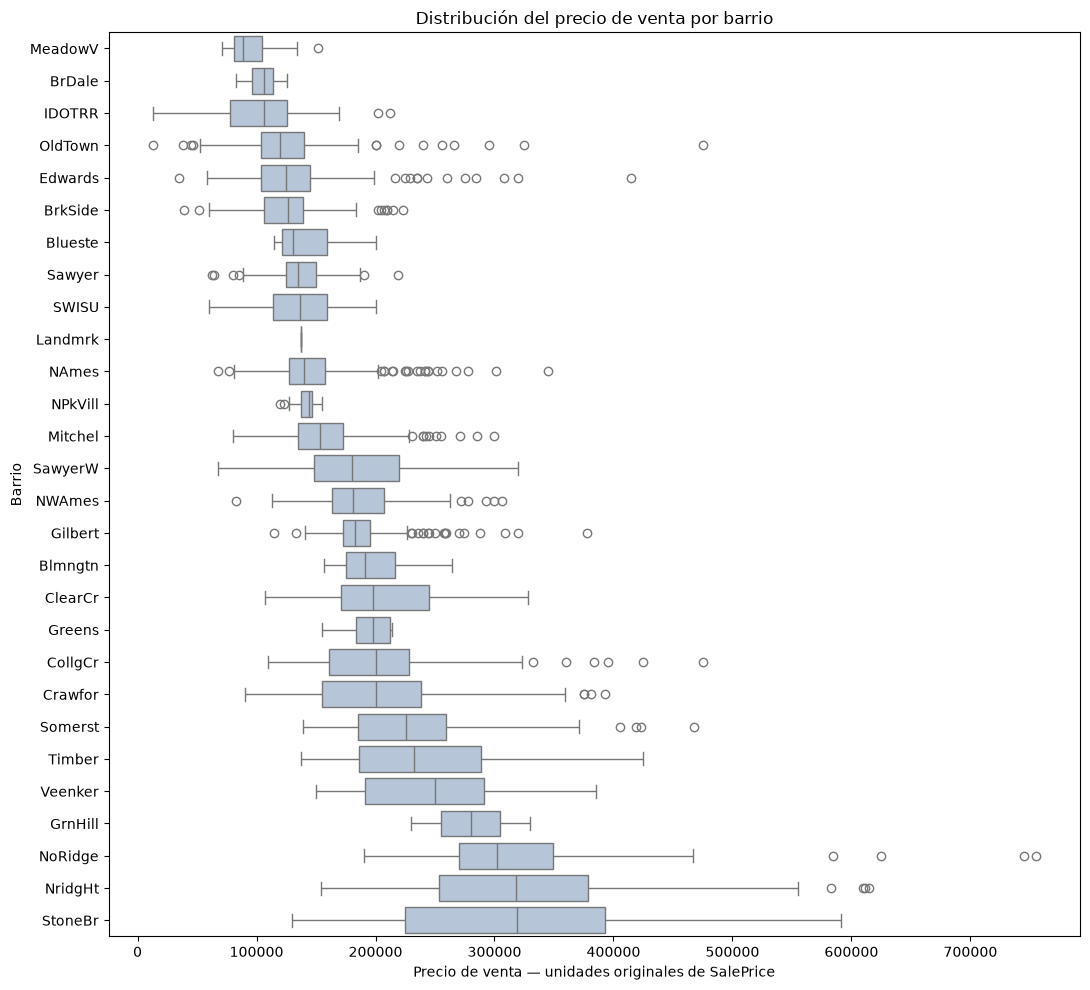

In [17]:
orden_barrios = resumen_barrio.index.tolist()

fig, ax = plt.subplots(figsize=(11, 10))

sns.boxplot(
    data=df,
    x="SalePrice",
    y="Neighborhood",
    order=orden_barrios,
    color="lightsteelblue",
    ax=ax
)

ax.set_title("Distribución del precio de venta por barrio")
ax.set_xlabel("Precio de venta — unidades originales de SalePrice")
ax.set_ylabel("Barrio")

fig.tight_layout()

fig.savefig(
    IMAGES_DIR / "eda_barrio_precio.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

#### Hallazgo 4: diferencias de precio entre barrios

Las medianas de SalePrice varían entre los barrios registrados.
Por ejemplo:

- MeadowV: mediana de 88.250, con 37 viviendas.
- NAmes: mediana de 140.000, con 443 viviendas.
- CollgCr: mediana de 200.000, con 267 viviendas.
- NoRidge: mediana de 302.000, con 71 viviendas.
- NridgHt: mediana de 317.750, con 166 viviendas.
- StoneBr: mediana de 319.000, con 51 viviendas.

Los tamaños de los grupos son desiguales. Landmrk tiene un solo registro
y GrnHill tiene dos, por lo que sus resultados no permiten caracterizar
de forma sólida la distribución de precios de esos barrios.

El gráfico muestra dispersión dentro de los barrios y superposición
entre sus distribuciones.

Implicancia para el negocio:
Neighborhood es una variable candidata relevante para contextualizar
la estimación de precios y comparar propiedades. Conviene evaluar
posteriormente si los errores del modelo varían entre barrios,
considerando la cantidad de registros disponible en cada grupo.

Limitación:
las diferencias observadas no representan un efecto aislado del barrio.
Pueden estar asociadas también con diferencias de superficie, calidad,
antigüedad y otras características de las viviendas. No permiten
atribuir características a sus habitantes.

### 3.5. Año de construcción y precio de venta

Se explora la relación entre Year Built y SalePrice para revisar
si el precio presenta diferencias asociadas al año de construcción.

Este análisis no controla por remodelaciones, calidad, superficie
o barrio. Además, existe una alerta temporal previamente identificada
en Year Built que se mantiene sin modificar durante el diagnóstico.

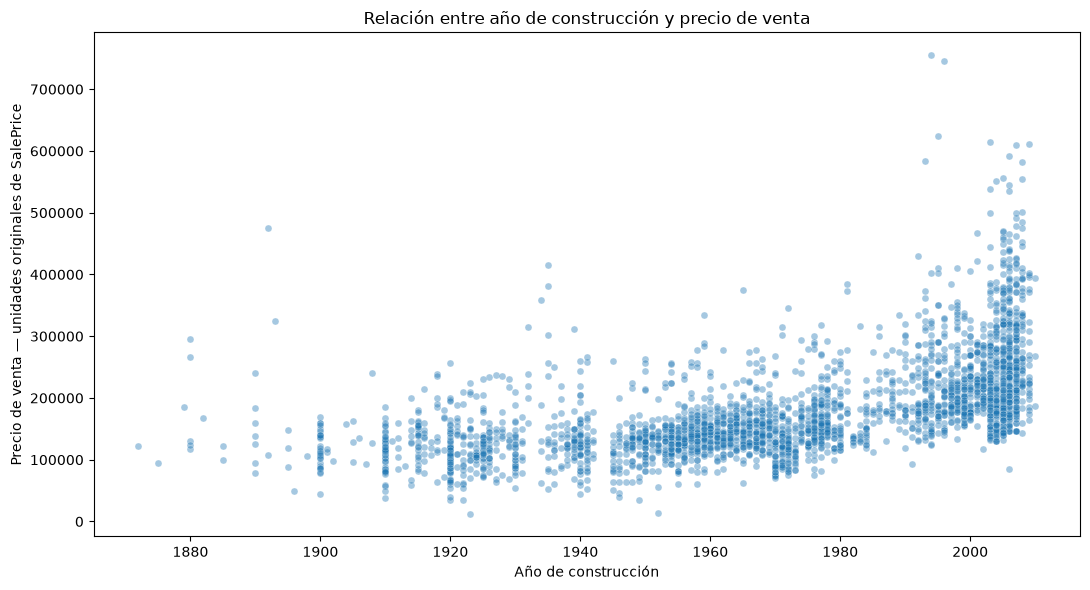

In [18]:
fig, ax = plt.subplots(figsize=(11, 6))

sns.scatterplot(
    data=df,
    x="Year Built",
    y="SalePrice",
    alpha=0.4,
    s=25,
    ax=ax
)

ax.set_title("Relación entre año de construcción y precio de venta")
ax.set_xlabel("Año de construcción")
ax.set_ylabel("Precio de venta — unidades originales de SalePrice")

fig.tight_layout()

fig.savefig(
    IMAGES_DIR / "eda_anio_construccion_precio.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [19]:
correlaciones_construccion = pd.Series({
    "Pearson": df["Year Built"].corr(
        df["SalePrice"],
        method="pearson"
    ),
    "Spearman": df["Year Built"].corr(
        df["SalePrice"],
        method="spearman"
    )
})

correlaciones_construccion.round(3)

Pearson     0.558
Spearman    0.681
dtype: float64

#### Hallazgo 5: año de construcción y precio

Year Built presenta una asociación positiva con SalePrice:
la correlación de Pearson es 0,558 y la de Spearman es 0,681.

El gráfico muestra que las viviendas construidas más recientemente
tienden a registrar precios superiores. Sin embargo, existe una
dispersión considerable de precios para años de construcción similares
y también se observan viviendas antiguas con precios elevados.

Implicancia para el negocio:
el año de construcción es una variable candidata para contextualizar
la estimación del precio, pero debe complementarse con calidad,
superficie, barrio y antecedentes de remodelación.

Limitación:
este análisis no permite aislar el efecto de la antigüedad ni afirmar
que una vivienda pierde una cantidad fija de valor por año.
La alerta temporal detectada previamente se mantiene pendiente
de tratamiento en la preparación de datos.

### 3.6. Correlaciones entre variables seleccionadas

Se presenta una matriz de correlación de Pearson para variables
relacionadas con calidad, superficies, capacidad del garaje,
año de construcción y precio.

Se excluyen los identificadores Order y PID. La selección corresponde
a una revisión exploratoria y no constituye la selección definitiva
de variables para los modelos.

Las correlaciones se interpretarán como asociaciones, no como
evidencia de causalidad ni como importancia predictiva definitiva.

In [20]:
variables_correlacion = [
    "Overall Qual",
    "Gr Liv Area",
    "Total Bsmt SF",
    "1st Flr SF",
    "Garage Cars",
    "Garage Area",
    "Year Built",
    "Year Remod/Add",
    "Lot Area",
    "SalePrice"
]

matriz_correlacion = df[variables_correlacion].corr(
    method="pearson"
)

correlaciones_precio = (
    matriz_correlacion["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
    .rename("correlacion_con_SalePrice")
)

correlaciones_precio.round(3)

Overall Qual      0.799
Gr Liv Area       0.707
Garage Cars       0.648
Garage Area       0.640
Total Bsmt SF     0.632
1st Flr SF        0.622
Year Built        0.558
Year Remod/Add    0.533
Lot Area          0.267
Name: correlacion_con_SalePrice, dtype: float64

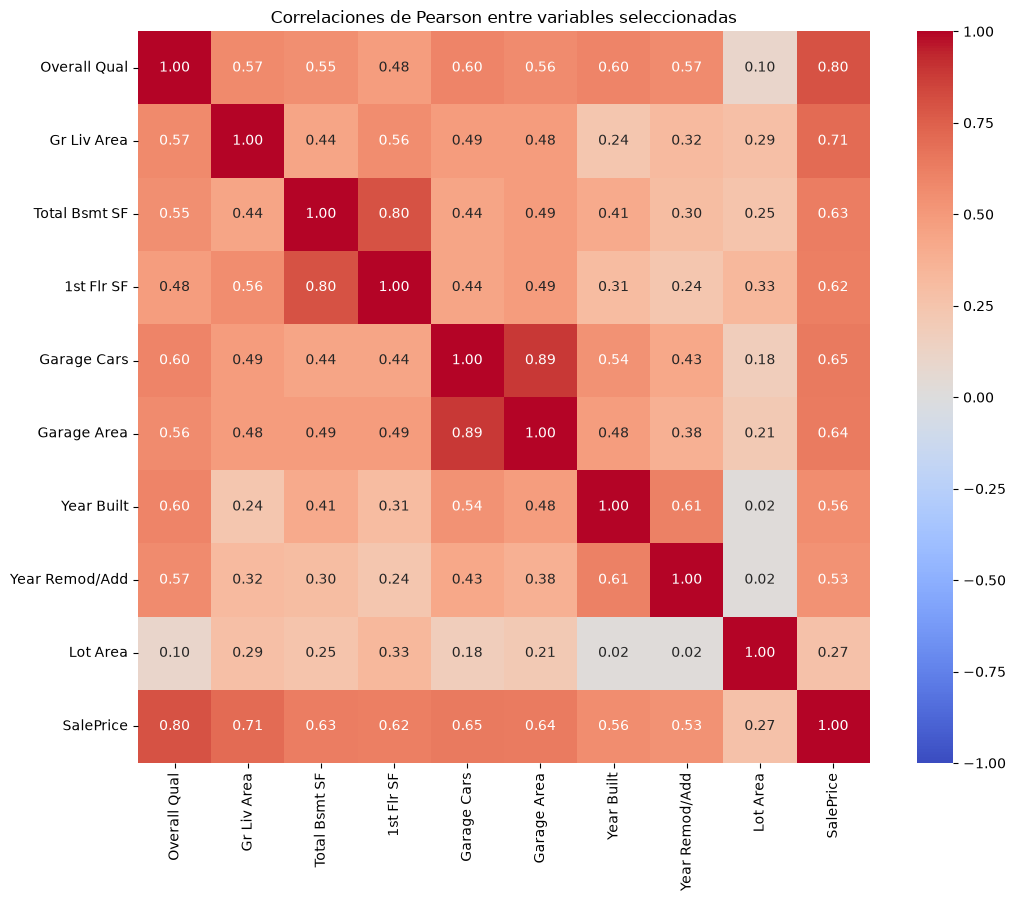

In [21]:
fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=ax
)

ax.set_title("Correlaciones de Pearson entre variables seleccionadas")

fig.tight_layout()

fig.savefig(
    IMAGES_DIR / "eda_matriz_correlaciones.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

#### Interpretación de las correlaciones

Entre las variables seleccionadas, Overall Qual presenta la mayor
correlación de Pearson con SalePrice (0,799), seguida de Gr Liv Area
(0,707).

También se observan asociaciones positivas entre el precio y
Garage Cars (0,648), Garage Area (0,640), Total Bsmt SF (0,632)
y 1st Flr SF (0,622).

Lot Area presenta una correlación lineal menor con SalePrice (0,267).
Esto no demuestra que sea irrelevante: su relación podría depender
de otras características o no quedar bien representada por una
correlación lineal.

La matriz también muestra relaciones elevadas entre algunos
predictores:

- Garage Cars y Garage Area: aproximadamente 0,89.
- Total Bsmt SF y 1st Flr SF: aproximadamente 0,80.

Estas relaciones se tendrán en cuenta durante el modelado y la
interpretación. No se eliminarán variables únicamente por superar
un umbral de correlación.

Limitaciones:
la matriz corresponde a variables seleccionadas, no a todas las
columnas del dataset. No incluye directamente variables categóricas
como Neighborhood y no representa una medida definitiva de
importancia

### 3.7. Síntesis del análisis exploratorio

El análisis permitió identificar cinco hallazgos principales:

1. SalePrice presenta asimetría hacia precios elevados.
2. La superficie habitable se asocia positivamente con el precio,
   pero no explica por sí sola sus diferencias.
3. Las medianas de precio aumentan con los niveles de calidad general.
4. Existen diferencias de precio entre barrios, con tamaños de
   muestra desiguales y superposición entre sus distribuciones.
5. El año de construcción presenta una asociación positiva con
   el precio, con variación considerable entre viviendas.

La matriz de correlaciones complementa estos hallazgos e identifica
relaciones entre predictores que deberán considerarse en el modelado.

Los resultados son exploratorios y no demuestran causalidad.
No se han eliminado registros ni seleccionado definitivamente
las variables del modelo.

El EDA se realizó sobre el dataset completo. Esta circunstancia
se documentará como una limitación del protocolo de evaluación.
En las siguientes etapas, las transformaciones aprendidas y la
selección de modelos se realizarán únicamente con entrenamiento,
sin utilizar el conjunto de prueba para ajustar decisiones.